# IND320 Data to Decision - Compulsory work, part 2

Reservoir data from the NVE Magasinstatistikk API, cross-border electricity flows for Norway,
a local Cassandra database (through Spark) and a remote MongoDB database used by the Streamlit app.

## Links

- **GitHub repository:** https://github.com/limmen20/limmen-streamlit-dashboard
- **Streamlit app:** https://limmen-app-dashboard.streamlit.app/
- **Screencast:** https://youtu.be/yvJXZM7oM7M

## Feedback from part 1

The feedback on part 1 suggested keeping the notebooks in their own folder in the GitHub repository.
Both notebooks are now in the `notebooks/` folder. The Streamlit app from part 1 has been updated
(same repository and app), building on the pages from part 1.

## AI usage

I used an AI assistant (Claude) as a coding helper in this part of the project. It helped me set up
Cassandra and Spark on Windows, find the right API endpoints, draft and comment the code for
downloading, storing and plotting the data in this notebook, and restructure the Streamlit app
(API connection, MongoDB connection and the new pages). The notebook was run from start to end and
the app was tested locally before deployment.

## Log

In this part the project moved from a static CSV file to live data sources and databases.

The first step was to replace `reservoirs.csv` with a direct connection to NVE's Magasinstatistikk
API. The endpoint `HentOffentligData` returns the same weekly data as the CSV file, so the code from
part 1 could be reused: the JSON response is turned into a pandas DataFrame, the Norwegian headers are
renamed and the date column is parsed. As in part 1, the rows are not sorted by date, so sorting is
needed before plotting. The endpoint `HentOmråder` lists the areas covered: the whole country (NO),
the five electricity price areas (EL, NO1-NO5) and three watercourse regions (VASS).

The second data source is cross-border physical flows between Norway and its neighbours (Sweden,
Denmark, Finland, Germany, the Netherlands and Great Britain) for the last two years. The ENTSO-E API
needs a personal security token. The code reads the token from a local secrets file, and if no token
is available it uses Energy-Charts (Fraunhofer ISE), which publishes the same ENTSO-E flow data
without a token. The flows are converted to hourly energy (MWh) in each direction.

The hourly data are written to a local Cassandra database with Spark. Cassandra was not available
through Docker on my computer, so I ran Cassandra 3.11 directly on Windows with Java 8, together with
PySpark 3.5 and the Spark-Cassandra connector. A problem was that time stamps are easily shifted by the
local time zone, so the Spark session runs in UTC and dates are converted to Norwegian time on purpose.
Spark is then used to read the relevant columns back from Cassandra and to sum the hourly values to
daily totals per connection and direction.

From these data I made a pie chart of the total flow into and out of Norway for one connection and
one year, and a line plot for the first month of a year with one line per connection and direction.
The daily totals are inserted into MongoDB, which the Streamlit app reads from.

In the Streamlit app the CSV file is replaced by the API. The Data table and Plot pages from part 1
now share their controls in the sidebar, so a choice made on one page is kept on the other: radio
buttons choose the area type (EL, NO or VASS), and the month slider from page three now controls which
period is downloaded. The table has one row per area number with LineChartColumn charts, and the plot
has one line per area number. The new page four uses two columns: radio buttons and a select box
choose connection and year for the pie chart, and pills choose the months in the line plot. The
placeholder that was on page four was moved to page five. The MongoDB connection string is stored in Streamlit secrets and
never pushed to GitHub. Following the feedback from part 1, the notebooks are now in their own folder.

## 1. Setup

In [1]:
# Libraries
import os
import sys
import tomllib                                  # to read secrets.toml
from pathlib import Path

import pandas as pd                             # data handling
import requests                                 # calling the web APIs
import matplotlib.pyplot as plt                 # plotting
from matplotlib.ticker import PercentFormatter
import matplotlib.dates as mdates

# The notebook is in notebooks/, so the project folder is one level up
ROOT = Path.cwd().parent

# Passwords/tokens are in .streamlit/secrets.toml (in .gitignore, so not on GitHub).
# The app uses the same file.
with open(ROOT / ".streamlit" / "secrets.toml", "rb") as f:
    secrets = tomllib.load(f)

# Plot style: light grid, no frame on top/right
plt.rcParams.update({
    "figure.figsize": (10, 3.5),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

## 2. Magasinstatistikk API (replaces the CSV file)

NVE's API ([swagger](https://biapi.nve.no/magasinstatistikk/swagger/index.html)) has four endpoints
without parameters:

| Endpoint | Content |
|---|---|
| `HentOffentligData` | All weekly reservoir statistics since 1995 (same content as the old CSV file) |
| `HentOffentligDataSisteUke` | Only the latest week |
| `HentOffentligDataMinMaxMedian` | Min, max and median for the last 20 years |
| `HentOmråder` | The areas used in the statistics |

### 2.1 Areas covered by the API

In [2]:
NVE_API = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk"

# Three groups: whole country, price areas and watercourse regions
areas_json = requests.get(f"{NVE_API}/HentOmråder", timeout=60).json()[0]   # a list with one dictionary
areas = pd.concat(
    [pd.DataFrame(areas_json[group]).assign(group=group) for group in ["land", "elspot", "vassdrag"]],
    ignore_index=True,
)
areas[["group", "omrType", "omrnr", "navn", "beskrivelse"]]

,group,omrType,omrnr,navn,beskrivelse
0,land,NO,0,Norge,Hele landet
1,elspot,EL,1,NO 1,Sørøst-Norge. Omfatter østlige del av Østlande...
2,elspot,EL,2,NO 2,Sørvest-Norge. Omfatter mesteparten av Vestfol...
3,elspot,EL,3,NO 3,Midt-Norge. Omfatter nordre og vestlige del av...
4,elspot,EL,4,NO 4,Nord-Norge. Omfatter resten av Trøndelag og No...
5,elspot,EL,5,NO 5,Vest-Norge. Omfatter midtre del av Vestland op...
6,vassdrag,VASS,1,VASS1,"Sørøst-Norge. Østlandet, Agder og deler av Rog..."
7,vassdrag,VASS,2,VASS2,Vest-Norge. Resten av Rogaland og Vestland.
8,vassdrag,VASS,3,VASS3,"Midt-Norge. Møre og Romsdal, Trøndelag og sørl..."
9,vassdrag,VASS,4,VASS4,Nord-Norge. Resten av Nordland og nordover.


NVE covers the **whole country (NO)**, the **five electricity price areas NO1-NO5 (EL)** and
**three watercourse regions (VASS)**. ENTSO-E (used in section 3) uses its own area codes (EIC codes)
for the same price areas and for the country as a whole:

| Area | ENTSO-E code |
|---|---|
| Norway (country) | `10YNO-0--------C` |
| NO1 South-East | `10YNO-1--------2` |
| NO2 South-West | `10YNO-2--------T` |
| NO3 Central | `10YNO-3--------J` |
| NO4 North | `10YNO-4--------9` |
| NO5 West | `10Y1001A1001A48H` |

### 2.2 Download the reservoir data

As in part 1, the headers are Norwegian, the date column is text and the rows are not sorted by date.
The same renaming and sorting as in part 1 is therefore applied.

In [3]:
# Get all the weekly data as JSON -> DataFrame
response = requests.get(f"{NVE_API}/HentOffentligData", timeout=60)
response.raise_for_status()
df = pd.DataFrame(response.json())
print("Rows downloaded:", len(df))

# Norwegian -> English column names (same as part 1 and the app)
column_names = {
    "dato_Id": "date",
    "omrType": "area_type",
    "omrnr": "area_number",
    "iso_aar": "iso_year",
    "iso_uke": "iso_week",
    "fyllingsgrad": "filling_ratio",
    "kapasitet_TWh": "capacity_TWh",
    "fylling_TWh": "filling_TWh",
    "neste_Publiseringsdato": "next_publication_date",
    "fyllingsgrad_forrige_uke": "filling_ratio_prev_week",
    "endring_fyllingsgrad": "filling_ratio_change",
}
df = df.rename(columns=column_names)

# Date comes as text, and the rows are not sorted (same as the CSV in part 1)
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values(["area_type", "area_number", "date"]).reset_index(drop=True)
print("Period:", df["date"].min().date(), "to", df["date"].max().date())
df.head()

Rows downloaded: 14922
Period: 1995-01-08 to 2026-10-11


,date,area_type,area_number,iso_year,iso_week,filling_ratio,capacity_TWh,filling_TWh,next_publication_date,filling_ratio_prev_week,filling_ratio_change
0,1995-01-08,EL,1,1995,1,0.617574,6.003264,3.707457,0001-01-01T00:00:00,0.583705,0.033869
1,1995-01-15,EL,1,1995,2,0.579205,6.003264,3.477117,0001-01-01T00:00:00,0.617574,-0.038369
2,1995-01-22,EL,1,1995,3,0.546713,6.003264,3.282063,0001-01-01T00:00:00,0.579205,-0.032491
3,1995-01-29,EL,1,1995,4,0.504545,6.003264,3.028916,0001-01-01T00:00:00,0.546713,-0.042168
4,1995-02-05,EL,1,1995,5,0.465335,6.003264,2.793528,0001-01-01T00:00:00,0.504545,-0.039210


In [4]:
# Weeks, period and capacity per area
df.groupby(["area_type", "area_number"]).agg(
    weeks=("date", "size"),
    first_date=("date", "min"),
    last_date=("date", "max"),
    capacity_TWh=("capacity_TWh", "mean"),
)

weeks first_date  last_date  capacity_TWh
area_type area_number                                           
EL        1             1658 1995-01-08 2026-10-11      6.003264
          2             1658 1995-01-08 2026-10-11     34.043590
          3             1658 1995-01-08 2026-10-11      8.920932
          4             1658 1995-01-08 2026-10-11     21.079208
          5             1658 1995-01-08 2026-10-11     17.390587
NO        0             1658 1995-01-08 2026-10-11     87.437580
VASS      1             1658 1995-01-08 2026-10-11     36.044464
          2             1658 1995-01-08 2026-10-11     23.237715
          3             1658 1995-01-08 2026-10-11     28.155403

### 2.3 Recreating the plots from part 1

The same plots as in part 1, now made from the API data: each measurement column separately for
Norway as a whole, and all columns together, scaled by their maximum absolute value so that they
share one axis.

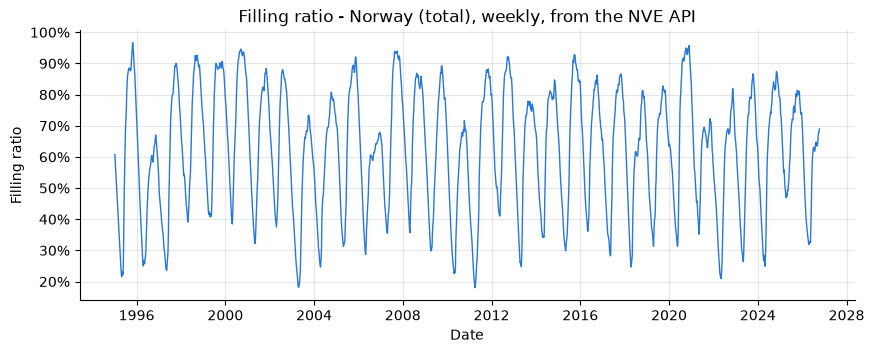

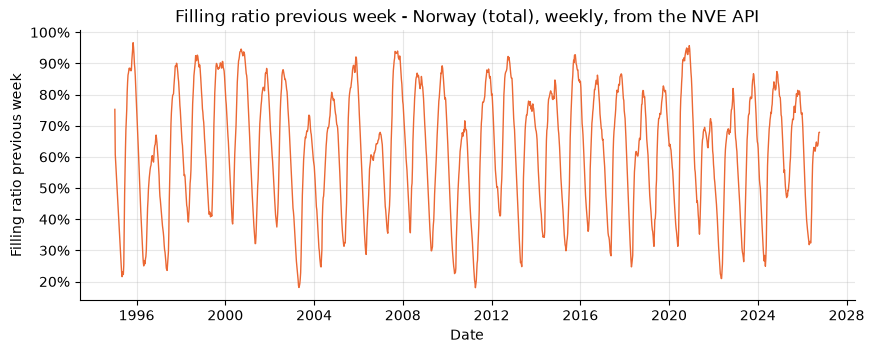

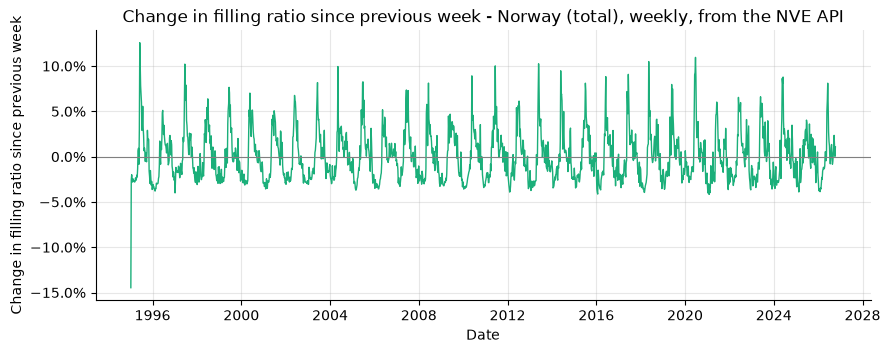

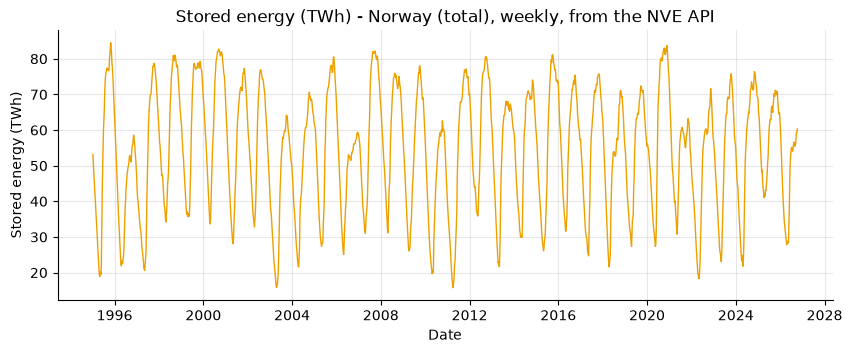

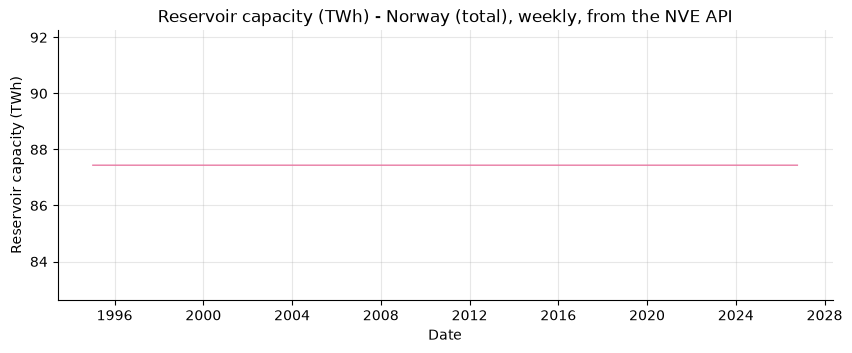

In [5]:
# Only the whole of Norway, date as index
norway = df[df["area_type"] == "NO"].set_index("date")

# The columns to plot, with labels and a fixed colour each
value_columns = {
    "filling_ratio": "Filling ratio",
    "filling_ratio_prev_week": "Filling ratio previous week",
    "filling_ratio_change": "Change in filling ratio since previous week",
    "filling_TWh": "Stored energy (TWh)",
    "capacity_TWh": "Reservoir capacity (TWh)",
}
colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
ratio_columns = ["filling_ratio", "filling_ratio_prev_week", "filling_ratio_change"]

# One figure per column
for (col, label), color in zip(value_columns.items(), colors):
    fig, ax = plt.subplots()
    ax.plot(norway.index, norway[col], color=color, linewidth=1)
    ax.set_title(f"{label} - Norway (total), weekly, from the NVE API")
    ax.set_xlabel("Date")
    ax.set_ylabel(label)
    if col in ratio_columns:
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))  # 0.5 -> 50 %
    if col == "filling_ratio_change":
        ax.axhline(0, color="grey", linewidth=0.8)
    plt.show()

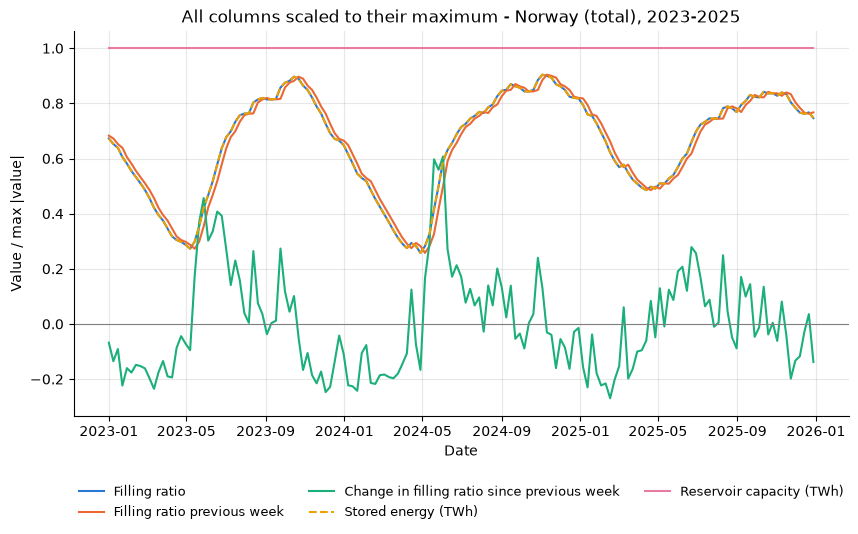

In [6]:
# All columns together: divide each column by its max so they share one axis
# (min-max scaling would divide by zero for capacity, which is constant)
scaled = norway[list(value_columns)] / norway[list(value_columns)].abs().max()
recent = scaled.loc["2023-01-01":"2025-12-31"]   # 3 full years, easier to read

fig, ax = plt.subplots(figsize=(10, 5))
for (col, label), color in zip(value_columns.items(), colors):
    style = "--" if col == "filling_TWh" else "-"   # stored energy overlaps the filling ratio, so dashed
    ax.plot(recent.index, recent[col], label=label, color=color, linewidth=1.5, linestyle=style)
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_title("All columns scaled to their maximum - Norway (total), 2023-2025")
ax.set_xlabel("Date")
ax.set_ylabel("Value / max |value|")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, fontsize=9, frameon=False)
plt.show()

## 3. Cross-border flows (ENTSO-E)

The ENTSO-E Transparency Platform publishes *cross-border physical flows* (document type A11) between
countries and price areas. Norway has interconnectors to six countries: Sweden, Denmark, Finland,
Germany, the Netherlands and Great Britain. For each of these *connections* we download the flow in
both directions (into and out of Norway) for the **last two years** (1 October 2024 to 1 October 2026).

The ENTSO-E API requires a personal security token. The token is read from the secrets file. If no
token is available yet, the same ENTSO-E flow data are downloaded from
[Energy-Charts](https://api.energy-charts.info/) (Fraunhofer ISE), which republishes them without a
token. Both sources give the same table: one row per hour, connection and direction, with the energy
in MWh.

In [7]:
# Last two years (Norwegian time)
START = pd.Timestamp("2024-10-01", tz="Europe/Oslo")
END = pd.Timestamp("2026-10-01", tz="Europe/Oslo")

# Neighbour countries: ENTSO-E code -> name
NEIGHBOURS = {"SE": "Sweden", "DK": "Denmark", "FI": "Finland",
              "DE": "Germany", "NL": "Netherlands", "GB": "Great Britain"}
IMPORT, EXPORT = "Import to Norway", "Export from Norway"


def to_hourly(mw: pd.Series) -> pd.Series:
    """Average MW over an hour = MWh in that hour (works for 15 and 60 min data)."""
    return mw.resample("1h").mean()


def fetch_flows_entsoe(token: str) -> pd.DataFrame:
    """Physical flows in both directions for every connection, from the ENTSO-E API."""
    from entsoe import EntsoePandasClient   # handles the ENTSO-E XML for us
    client = EntsoePandasClient(api_key=token)
    frames = []
    for code, name in NEIGHBOURS.items():
        for from_area, to_area, direction in [(code, "NO", IMPORT), ("NO", code, EXPORT)]:
            try:
                mw = client.query_crossborder_flows(from_area, to_area, start=START, end=END)
            except Exception as error:   # e.g. no data for this border
                print(f"No data for {from_area} -> {to_area}: {error}")
                continue
            hourly = to_hourly(mw)
            frames.append(pd.DataFrame({"connection": name, "direction": direction,
                                        "time": hourly.index, "mwh": hourly.values}))
    return pd.concat(frames, ignore_index=True)


def fetch_flows_energy_charts() -> pd.DataFrame:
    """The same ENTSO-E flows from Energy-Charts: net flow per neighbour in GW (+ import, - export)."""
    frames = []
    # One request per year (1 Oct - 30 Sep)
    for year_start in pd.date_range(START, END, freq="12MS", inclusive="left"):
        year_end = year_start + pd.DateOffset(years=1) - pd.Timedelta(days=1)
        params = {"country": "no", "start": year_start.strftime("%Y-%m-%d"), "end": year_end.strftime("%Y-%m-%d")}
        data = requests.get("https://api.energy-charts.info/cbpf", params=params, timeout=120).json()
        times = pd.to_datetime(data["unix_seconds"], unit="s", utc=True)
        for country in data["countries"]:
            if country["name"] == "sum":
                continue
            name = "Great Britain" if country["name"] == "United Kingdom" else country["name"]
            mw = pd.Series(country["data"], index=times, dtype=float) * 1000   # GW -> MW
            # Net flow: positive = into Norway, negative = out. Split before averaging
            for direction, part in [(IMPORT, mw.clip(lower=0)), (EXPORT, (-mw).clip(lower=0))]:
                hourly = to_hourly(part)
                frames.append(pd.DataFrame({"connection": name, "direction": direction,
                                            "time": hourly.index, "mwh": hourly.values}))
    return pd.concat(frames, ignore_index=True)


# ENTSO-E if I have a token, otherwise Energy-Charts
token = secrets.get("entsoe", {}).get("token", "")
if token and not token.startswith("PASTE"):
    SOURCE = "ENTSO-E Transparency Platform"
    flows = fetch_flows_entsoe(token)
else:
    SOURCE = "Energy-Charts (ENTSO-E data)"
    flows = fetch_flows_energy_charts()

# Keep only the two years, times in UTC, drop empty hours
flows["time"] = pd.to_datetime(flows["time"], utc=True)
flows = flows[(flows["time"] >= START) & (flows["time"] < END)].dropna(subset=["mwh"])
flows["source"] = SOURCE
print("Source:", SOURCE)
print("Rows (hours x connections x directions):", len(flows))
flows.head()

Source: Energy-Charts (ENTSO-E data)
Rows (hours x connections x directions): 210240


,connection,direction,time,mwh,source
0,Denmark,Import to Norway,2024-09-30 22:00:00+00:00,1344.0,Energy-Charts (ENTSO-E data)
1,Denmark,Import to Norway,2024-09-30 23:00:00+00:00,1187.0,Energy-Charts (ENTSO-E data)
2,Denmark,Import to Norway,2024-10-01 00:00:00+00:00,1112.0,Energy-Charts (ENTSO-E data)
3,Denmark,Import to Norway,2024-10-01 01:00:00+00:00,1222.0,Energy-Charts (ENTSO-E data)
4,Denmark,Import to Norway,2024-10-01 02:00:00+00:00,1332.0,Energy-Charts (ENTSO-E data)


In [8]:
# Quick check: total TWh per connection and direction
(flows.groupby(["connection", "direction"])["mwh"].sum() / 1e6).round(2).unstack()

direction,Export from Norway,Import to Norway
connection,,
Denmark,14.07,3.92
Finland,0.60,0.09
Germany,13.58,3.03
Great Britain,17.56,1.79
Netherlands,4.55,1.14
Sweden,5.69,14.58


## 4. Cassandra and Spark

Cassandra runs locally on port 9042. Docker was not available on my computer, so Cassandra 3.11 runs
directly on Windows (`bin\cassandra.bat -f`, with Java 8). With Docker the book's command
`docker run --name my_cassandra -p 9042:9042 cassandra:latest` gives the same result.

Spark connects to Cassandra with the DataStax Spark-Cassandra connector, as in the book.

### 4.1 Test the connection and create the table

In [9]:
from cassandra.cluster import Cluster

# Connect to Cassandra on my PC
cluster = Cluster(["localhost"], port=9042)
session = cluster.connect()

# Keyspace + table. (connection, direction) is the partition key, so each series is stored
# together, and time is the clustering key, so rows are kept in time order.
session.execute("""
    CREATE KEYSPACE IF NOT EXISTS ind320
    WITH REPLICATION = {'class': 'SimpleStrategy', 'replication_factor': 1};
""")
session.execute("""
    CREATE TABLE IF NOT EXISTS ind320.cross_border_flows (
        connection text, direction text, time timestamp, mwh double, source text,
        PRIMARY KEY ((connection, direction), time)
    );
""")
session.execute("TRUNCATE ind320.cross_border_flows;")   # empty the table each run
print("Cassandra version:", session.execute("SELECT release_version FROM system.local").one().release_version)

Cassandra version: 3.11.19


### 4.2 Start Spark

In [10]:
# PySpark settings for my PC (change the paths on another computer):
# - Java 8 (newer Java gave problems writing to Cassandra on Windows)
# - winutils = Hadoop for Windows (github.com/kontext-tech/winutils, hadoop-3.3.1)
os.environ["JAVA_HOME"] = r"C:\Program Files\Java\jre1.8.0_491"
os.environ["HADOOP_HOME"] = r"C:\Users\limmen\tools\hadoop-3.3.1"
os.environ["PATH"] = os.environ["HADOOP_HOME"] + r"\bin;" + os.environ["PATH"]
os.environ["PYSPARK_PYTHON"] = sys.executable          # same Python as the notebook
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = (
    SparkSession.builder.appName("IND320_part2")
    .config("spark.jars.packages", "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1")
    .config("spark.cassandra.connection.host", "localhost")
    .config("spark.cassandra.connection.port", "9042")
    .config("spark.sql.extensions", "com.datastax.spark.connector.CassandraSparkExtensions")
    .config("spark.sql.session.timeZone", "UTC")   # so times are not shifted by my time zone
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")   # less Spark spam
print("Spark version:", spark.version)

Spark version: 3.5.9


### 4.3 Insert the flows into Cassandra with Spark

In [11]:
# pandas rows -> Spark DataFrame. Times are given as UTC datetimes so they end up right in Cassandra
rows = list(zip(
    flows["connection"], flows["direction"],
    flows["time"].dt.to_pydatetime(), flows["mwh"].astype(float), flows["source"],
))
flows_spark = spark.createDataFrame(
    rows, schema="connection string, direction string, time timestamp, mwh double, source string"
)

# Write to Cassandra
(flows_spark.write.format("org.apache.spark.sql.cassandra")
    .options(table="cross_border_flows", keyspace="ind320")
    .mode("append").save())

print("Rows in Cassandra:", session.execute("SELECT COUNT(*) FROM ind320.cross_border_flows").one().count)

Rows in Cassandra: 210240


### 4.4 Extract the relevant columns with Spark

Spark reads the table back from Cassandra and keeps only the columns needed later (connection,
direction, time and energy). The hourly values are summed to **daily totals in GWh**, using Norwegian
dates. These daily totals are what the plots and the Streamlit app use.

In [12]:
# Read the table back from Cassandra and make a view for SQL
(spark.read.format("org.apache.spark.sql.cassandra")
    .options(table="cross_border_flows", keyspace="ind320").load()
    .select("connection", "direction", "time", "mwh")      # only the columns I need
    .createOrReplaceTempView("flows"))

# Sum per day, connection and direction (Norwegian dates)
daily_spark = spark.sql("""
    SELECT connection, direction,
           to_date(from_utc_timestamp(time, 'Europe/Oslo')) AS date,
           SUM(mwh) / 1000 AS gwh
    FROM flows
    GROUP BY connection, direction, to_date(from_utc_timestamp(time, 'Europe/Oslo'))
    ORDER BY connection, direction, date
""")
daily_spark.show(5)

# Small result -> pandas, plus year and month for filtering
daily = pd.DataFrame([row.asDict() for row in daily_spark.collect()])
daily["date"] = pd.to_datetime(daily["date"])
daily["year"] = daily["date"].dt.year
daily["month"] = daily["date"].dt.month
print("Daily rows:", len(daily))

+----------+------------------+----------+------+
|connection|         direction|      date|   gwh|
+----------+------------------+----------+------+
|   Denmark|Export from Norway|2024-10-01|12.245|
|   Denmark|Export from Norway|2024-10-02|28.075|
|   Denmark|Export from Norway|2024-10-03|31.333|
|   Denmark|Export from Norway|2024-10-04|35.107|
|   Denmark|Export from Norway|2024-10-05|38.443|
+----------+------------------+----------+------+
only showing top 5 rows



Daily rows: 8760


## 5. Plots of the cross-border flows

In [13]:
# Same colours as in the app
connection_colors = {"Sweden": "#2a78d6", "Denmark": "#eb6834", "Finland": "#1baf7a",
                     "Germany": "#eda100", "Netherlands": "#e87ba4", "Great Britain": "#008300"}
direction_colors = {IMPORT: "#2a78d6", EXPORT: "#eb6834"}

### 5.1 Pie chart: total flow in and out of Norway for one connection and one year

2025 is the only full calendar year in the two-year period (2024 starts in October, 2026 ends in
September).

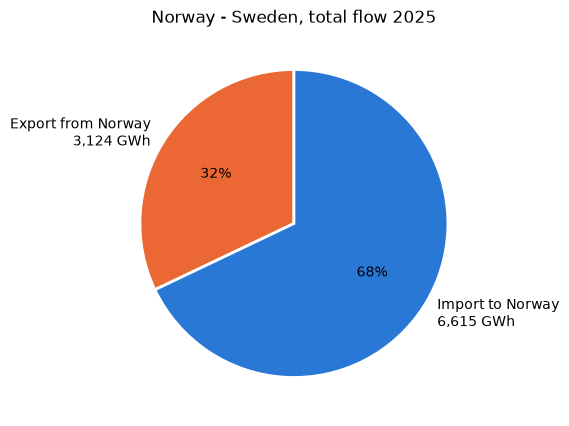

In [14]:
CHOSEN_CONNECTION = "Sweden"
CHOSEN_YEAR = 2025

# Total in and out for the chosen connection and year
totals = (daily[(daily["connection"] == CHOSEN_CONNECTION) & (daily["year"] == CHOSEN_YEAR)]
          .groupby("direction")["gwh"].sum())

fig, ax = plt.subplots(figsize=(5, 5))
ax.pie(
    totals.values,
    labels=[f"{d}\n{v:,.0f} GWh" for d, v in totals.items()],
    colors=[direction_colors[d] for d in totals.index],
    autopct="%1.0f%%", startangle=90,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 10},
)
ax.set_title(f"Norway - {CHOSEN_CONNECTION}, total flow {CHOSEN_YEAR}")
plt.show()

### 5.2 Line plot: first month of a year, one line per connection and direction

Colour shows the connection and the line style shows the direction (solid = into Norway,
dashed = out of Norway).

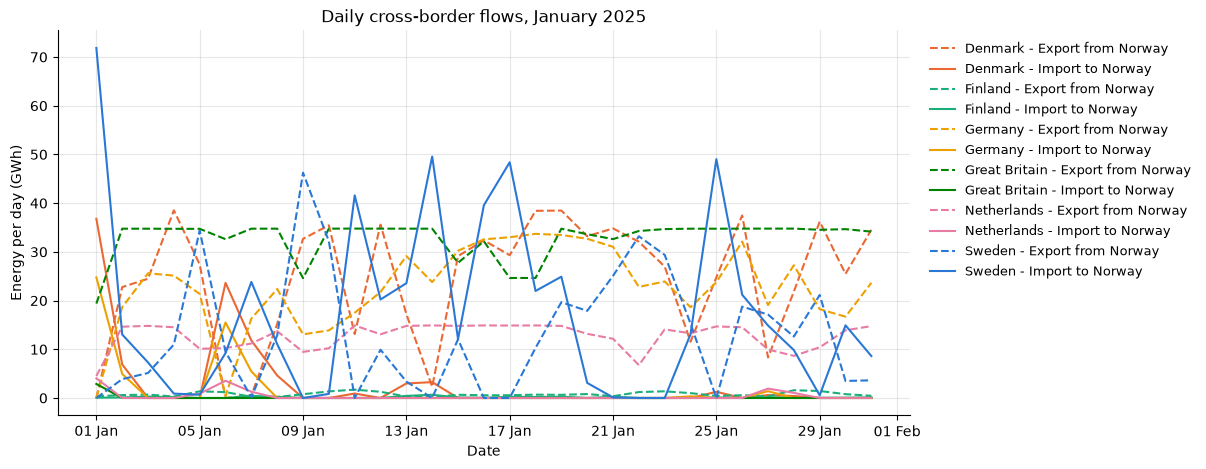

In [15]:
CHOSEN_CONNECTIONS = list(NEIGHBOURS.values())   # all connections (shorter list = fewer lines)
first_month = daily[(daily["year"] == CHOSEN_YEAR) & (daily["month"] == 1)
                    & daily["connection"].isin(CHOSEN_CONNECTIONS)]

fig, ax = plt.subplots(figsize=(11, 5))
for (connection, direction), group in first_month.groupby(["connection", "direction"]):
    ax.plot(group["date"], group["gwh"],
            color=connection_colors[connection],
            linestyle="-" if direction == IMPORT else "--",
            linewidth=1.5, label=f"{connection} - {direction}")
ax.set_title(f"Daily cross-border flows, January {CHOSEN_YEAR}")
ax.set_xlabel("Date")
ax.set_ylabel("Energy per day (GWh)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))   # e.g. "05 Jan"
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9, frameon=False)
plt.show()

## 6. MongoDB

The Spark-extracted daily totals are inserted into a MongoDB Atlas database (free tier), where the
Streamlit app reads them. The connection string is read from the secrets file.

In [16]:
from pymongo import MongoClient

# Connect and ping to test
client = MongoClient(secrets["mongo"]["uri"])
client.admin.command("ping")
print("Connected to MongoDB")

collection = client["ind320"]["cross_border_flows_daily"]

Connected to MongoDB


In [17]:
# Replace old data with the new daily values (one document per day, connection and direction)
documents = daily.assign(date=daily["date"].dt.to_pydatetime(), source=SOURCE).to_dict("records")
collection.delete_many({})
collection.insert_many(documents)
collection.create_index([("year", 1), ("connection", 1)])   # the app filters on these

print("Documents in MongoDB:", collection.count_documents({}))
collection.find_one({}, {"_id": 0})

Documents in MongoDB: 8760


{'connection': 'Denmark',
 'direction': 'Export from Norway',
 'date': datetime.datetime(2024, 10, 1, 0, 0),
 'gwh': 12.245,
 'year': 2024,
 'month': 10,
 'source': 'Energy-Charts (ENTSO-E data)'}

In [18]:
# Testing MongoDB from Python: yearly totals with an aggregation pipeline
pipeline = [
    {"$group": {"_id": {"year": "$year", "connection": "$connection", "direction": "$direction"},
                "gwh": {"$sum": "$gwh"}}},
    {"$sort": {"_id.year": 1, "_id.connection": 1}},
]
yearly = pd.DataFrame([{**d["_id"], "gwh": round(d["gwh"])} for d in collection.aggregate(pipeline)])
yearly.pivot_table(index=["year", "connection"], columns="direction", values="gwh")

direction           Export from Norway  Import to Norway
year connection                                         
2024 Denmark                    2343.0             196.0
     Finland                      71.0              12.0
     Germany                    1915.0             113.0
     Great Britain              2389.0              14.0
     Netherlands                1105.0              47.0
     Sweden                      597.0            2652.0
2025 Denmark                    8156.0            1152.0
     Finland                     277.0              47.0
     Germany                    7787.0             766.0
     Great Britain              9762.0             450.0
     Netherlands                2789.0             413.0
     Sweden                     3124.0            6615.0
2026 Denmark                    3574.0            2570.0
     Finland                     250.0              29.0
     Germany                    3875.0            2152.0
     Great Britain              5413.0            1323.0
     Netherlands                 653.0             677.0
     Sweden                     1969.0            5314.0

In [19]:
# Close everything
spark.stop()
cluster.shutdown()
client.close()